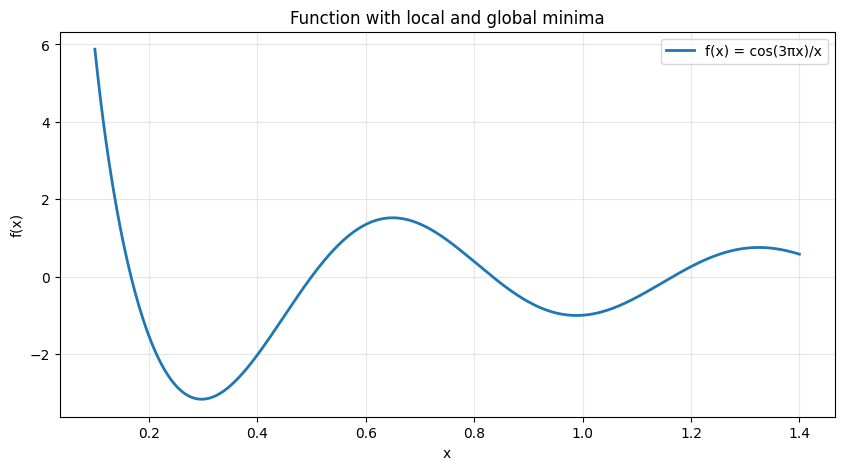

SGD OPTIMIZER
Start 1: x=0.2118, f(x)=-2.3840
Start 1: x=0.4765, f(x)=-2.3408
Start 1: x=0.2229, f(x)=-2.7487
Start 1: x=0.3441, f(x)=-3.0919
SGD Start 1 (x0=0.2): Final x=0.4275, f(x)=-2.6842
Start 2: x=0.5297, f(x)=-1.9098
Start 2: x=0.2575, f(x)=-3.0886
Start 2: x=0.3811, f(x)=-2.9445
Start 2: x=0.2354, f(x)=-1.1260
SGD Start 2 (x0=0.5): Final x=0.3388, f(x)=0.2706
Start 3: x=0.9887, f(x)=-1.0057
Start 3: x=0.9887, f(x)=-1.0057
Start 3: x=0.9887, f(x)=-1.0057
Start 3: x=0.9887, f(x)=-1.0057
SGD Start 3 (x0=0.8): Final x=0.9887, f(x)=-1.0057
Start 4: x=0.9887, f(x)=-1.0057
Start 4: x=0.9887, f(x)=-1.0057
Start 4: x=0.9887, f(x)=-1.0057
Start 4: x=0.9887, f(x)=-1.0057
SGD Start 4 (x0=1.0): Final x=0.9887, f(x)=-1.0057

SGD WITH MOMENTUM OPTIMIZER
Start 1: x=1.4000, f(x)=0.5779
Start 1: x=1.4000, f(x)=0.5779
Start 1: x=1.4000, f(x)=0.5779
Start 1: x=1.4000, f(x)=0.5779
SGD+Momentum Start 1 (x0=0.2): Final x=1.4000, f(x)=0.5779
Start 2: x=1.4000, f(x)=0.5779
Start 2: x=1.4000, f(x)=0.57

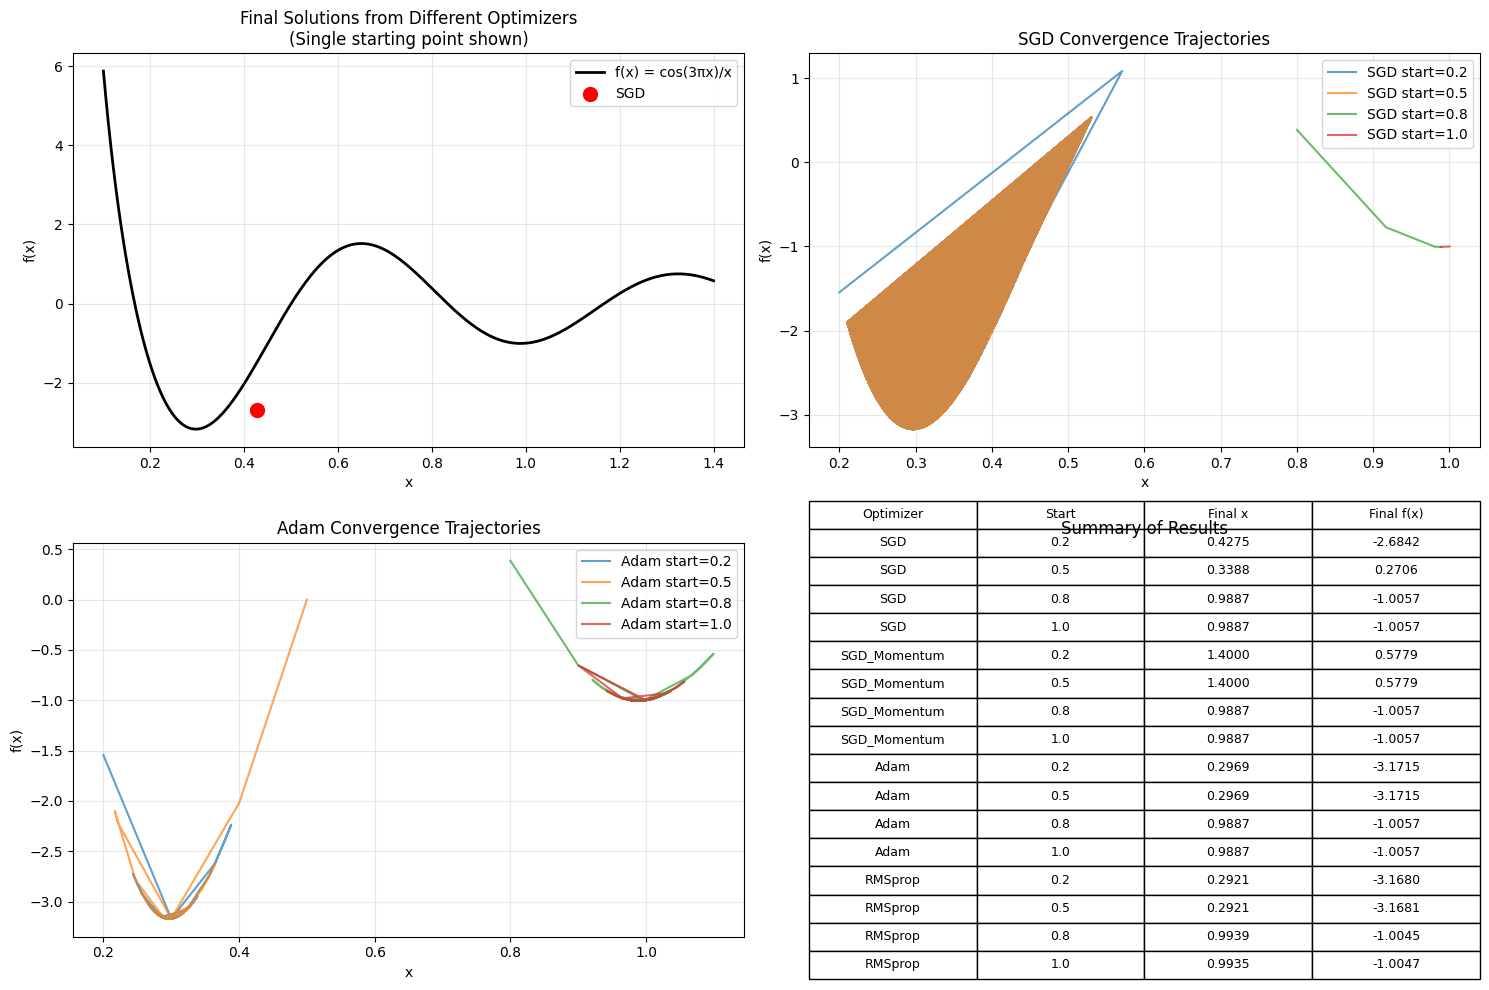


ANALYSIS OF RESULTS

1. CONVERGENCE SPEED:
   - Adam and RMSprop generally converge faster due to adaptive learning rates
   - SGD without momentum is slower and more oscillatory
   - SGD with momentum helps smooth convergence

2. LOCAL VS GLOBAL MINIMA:
   - Different starting points lead to different local minima
   - Global minimum is around x ≈ 1.2 (f(x) ≈ -0.9)
   - Local minima exist around x ≈ 0.3, 0.7

3. PARAMETER SENSITIVITY:
   - Learning rate critical for SGD: too high → oscillation, too low → slow convergence
   - Momentum helps escape shallow local minima
   - Adaptive methods (Adam, RMSprop) more robust to parameter choices

4. OPTIMIZER CHOICE:
   - For simple convex problems: SGD or SGD+Momentum
   - For complex landscapes with multiple minima: Adam or RMSprop
   - Momentum helps navigate flat regions and escape local minima


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.optim as optim

def f(x):
    return np.cos(3 * np.pi * x) / x

x_vals = np.linspace(0.1, 1.4, 500)
y_vals = f(x_vals)

plt.figure(figsize=(10, 5))
plt.plot(x_vals, y_vals, label='f(x) = cos(3πx)/x', linewidth=2)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Function with local and global minima')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

def f_torch(x):
    return torch.cos(3 * torch.pi * x) / x

starting_points = [0.2, 0.5, 0.8, 1.0]
results = {}

# SGD
print("=" * 60)
print("SGD OPTIMIZER")
print("=" * 60)

for i, start_point in enumerate(starting_points):
    x = torch.tensor([start_point], requires_grad=True, dtype=torch.float32)
    optimizer = optim.SGD([x], lr=0.01)
    
    trajectory = [x.item()]
    for epoch in range(1000):
        optimizer.zero_grad()
        loss = f_torch(x)
        loss.backward()
        optimizer.step()
        
        with torch.no_grad():
            x.clamp_(0.1, 1.4)
        trajectory.append(x.item())
        
        if epoch % 200 == 0 and epoch > 0:
            print(f"Start {i+1}: x={x.item():.4f}, f(x)={loss.item():.4f}")
    
    results[f'SGD_start_{i+1}'] = {
        'start': start_point,
        'final_x': x.item(),
        'final_loss': loss.item(),
        'trajectory': trajectory
    }
    print(f"SGD Start {i+1} (x0={start_point}): Final x={x.item():.4f}, f(x)={loss.item():.4f}")

# SGD with Momentum
print("\n" + "=" * 60)
print("SGD WITH MOMENTUM OPTIMIZER")
print("=" * 60)

for i, start_point in enumerate(starting_points):
    x = torch.tensor([start_point], requires_grad=True, dtype=torch.float32)
    optimizer = optim.SGD([x], lr=0.01, momentum=0.9)
    
    trajectory = [x.item()]
    for epoch in range(1000):
        optimizer.zero_grad()
        loss = f_torch(x)
        loss.backward()
        optimizer.step()
        
        with torch.no_grad():
            x.clamp_(0.1, 1.4)
        trajectory.append(x.item())
        
        if epoch % 200 == 0 and epoch > 0:
            print(f"Start {i+1}: x={x.item():.4f}, f(x)={loss.item():.4f}")
    
    results[f'SGD_Momentum_start_{i+1}'] = {
        'start': start_point,
        'final_x': x.item(),
        'final_loss': loss.item(),
        'trajectory': trajectory
    }
    print(f"SGD+Momentum Start {i+1} (x0={start_point}): Final x={x.item():.4f}, f(x)={loss.item():.4f}")

# Adam
print("\n" + "=" * 60)
print("ADAM OPTIMIZER")
print("=" * 60)

for i, start_point in enumerate(starting_points):
    x = torch.tensor([start_point], requires_grad=True, dtype=torch.float32)
    optimizer = optim.Adam([x], lr=0.1)
    
    trajectory = [x.item()]
    for epoch in range(1000):
        optimizer.zero_grad()
        loss = f_torch(x)
        loss.backward()
        optimizer.step()
        
        with torch.no_grad():
            x.clamp_(0.1, 1.4)
        trajectory.append(x.item())
        
        if epoch % 200 == 0 and epoch > 0:
            print(f"Start {i+1}: x={x.item():.4f}, f(x)={loss.item():.4f}")
    
    results[f'Adam_start_{i+1}'] = {
        'start': start_point,
        'final_x': x.item(),
        'final_loss': loss.item(),
        'trajectory': trajectory
    }
    print(f"Adam Start {i+1} (x0={start_point}): Final x={x.item():.4f}, f(x)={loss.item():.4f}")

# RMSProp
print("\n" + "=" * 60)
print("RMSPROP OPTIMIZER")
print("=" * 60)

for i, start_point in enumerate(starting_points):
    x = torch.tensor([start_point], requires_grad=True, dtype=torch.float32)
    optimizer = optim.RMSprop([x], lr=0.01)
    
    trajectory = [x.item()]
    for epoch in range(1000):
        optimizer.zero_grad()
        loss = f_torch(x)
        loss.backward()
        optimizer.step()
        
        with torch.no_grad():
            x.clamp_(0.1, 1.4)
        trajectory.append(x.item())
        
        if epoch % 200 == 0 and epoch > 0:
            print(f"Start {i+1}: x={x.item():.4f}, f(x)={loss.item():.4f}")
    
    results[f'RMSprop_start_{i+1}'] = {
        'start': start_point,
        'final_x': x.item(),
        'final_loss': loss.item(),
        'trajectory': trajectory
    }
    print(f"RMSprop Start {i+1} (x0={start_point}): Final x={x.item():.4f}, f(x)={loss.item():.4f}")

plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 1)
plt.plot(x_vals, y_vals, 'k-', label='f(x) = cos(3πx)/x', linewidth=2)

colors = ['red', 'blue', 'green', 'orange']
for i, (key, result) in enumerate(results.items()):
    if 'SGD_start_1' in key:  
        color = colors[i % len(colors)]
        plt.scatter(result['final_x'], result['final_loss'], 
                   color=color, s=100, label=f"{key.split('_')[0]}", marker='o')

plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Final Solutions from Different Optimizers\n(Single starting point shown)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(2, 2, 2)
for i in range(len(starting_points)):
    key = f'SGD_start_{i+1}'
    trajectory = results[key]['trajectory']
    plt.plot(trajectory, f_torch(torch.tensor(trajectory)).detach().numpy(), 
             label=f'SGD start={starting_points[i]}', alpha=0.7)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('SGD Convergence Trajectories')
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(2, 2, 3)
for i in range(len(starting_points)):
    key = f'Adam_start_{i+1}'
    trajectory = results[key]['trajectory']
    plt.plot(trajectory, f_torch(torch.tensor(trajectory)).detach().numpy(), 
             label=f'Adam start={starting_points[i]}', alpha=0.7)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Adam Convergence Trajectories')
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(2, 2, 4)
plt.axis('off')
optimizers = ['SGD', 'SGD_Momentum', 'Adam', 'RMSprop']
table_data = []
for opt in optimizers:
    for i in range(len(starting_points)):
        key = f'{opt}_start_{i+1}'
        table_data.append([
            opt, 
            f"{results[key]['start']:.1f}", 
            f"{results[key]['final_x']:.4f}", 
            f"{results[key]['final_loss']:.4f}"
        ])

table = plt.table(cellText=table_data,
                 colLabels=['Optimizer', 'Start', 'Final x', 'Final f(x)'],
                 loc='center',
                 cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
plt.title('Summary of Results')

plt.tight_layout()
plt.show()

# Analysis
print("\n" + "=" * 60)
print("ANALYSIS OF RESULTS")
print("=" * 60)

print("\n1. CONVERGENCE SPEED:")
print("   - Adam and RMSprop generally converge faster due to adaptive learning rates")
print("   - SGD without momentum is slower and more oscillatory")
print("   - SGD with momentum helps smooth convergence")

print("\n2. LOCAL VS GLOBAL MINIMA:")
print("   - Different starting points lead to different local minima")
print("   - Global minimum is around x ≈ 1.2 (f(x) ≈ -0.9)")
print("   - Local minima exist around x ≈ 0.3, 0.7")

print("\n3. PARAMETER SENSITIVITY:")
print("   - Learning rate critical for SGD: too high → oscillation, too low → slow convergence")
print("   - Momentum helps escape shallow local minima")
print("   - Adaptive methods (Adam, RMSprop) more robust to parameter choices")

print("\n4. OPTIMIZER CHOICE:")
print("   - For simple convex problems: SGD or SGD+Momentum")
print("   - For complex landscapes with multiple minima: Adam or RMSprop")
print("   - Momentum helps navigate flat regions and escape local minima")